# Membership Inference Attacks
### Measuring Training Data Leakage and Defenses

**Author:** Aakash Tiwari · M.S. Cybersecurity, Rowan University

**Objective:** measure how much a trained model reveals about which records were in its training data, and which defenses reduce that leakage.

| # | Section | Output |
|---|---|---|
| 1 | Data | Fig 1 |
| 2 | Why the attack works | Fig 2, Table 1 |
| 3 | Memorization vs leakage (5 seeds) | Fig 3–4, Table 2 |
| 4 | Shadow model attack | Fig 5–6, Table 3 |
| 5 | Training set size | Fig 7 |
| 6 | Defenses | Fig 8–10, Table 4 |
| 7 | Who is most at risk | Fig 11, Table 5 |
| 8 | Summary | Table 6 |

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option('display.precision', 3)

# Consistent figure style
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False,
})
C = {'member': '#2E75B6', 'nonmember': '#ED7D31', 'attack': '#C00000',
     'shadow': '#7030A0', 'guess': '#7F7F7F', 'good': '#548235'}

def save(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight')
    plt.show()

In [2]:
def true_label_confidence(model, X, y):
    """Probability the model assigns to the true label (confidence attack score)."""
    p = model.predict_proba(X)
    return p[np.arange(len(y)), y]

def tpr_at_fpr(labels, scores, target_fpr=0.01):
    """True positive rate at a fixed false positive rate."""
    fpr, tpr, _ = roc_curve(labels, scores)
    return tpr[np.searchsorted(fpr, target_fpr, side='right') - 1]

def evaluate(labels, scores):
    return {'attack_auc': roc_auc_score(labels, scores), 'tpr_at_1pct_fpr': tpr_at_fpr(labels, scores)}

def forest(depth=None, seed=0, **kw):
    return RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=seed, n_jobs=-1, **kw)

## 1. Data
Adult Census Income (UCI, Becker & Kohavi 1996). Task: predict income > $50K.

In [3]:
url = 'https://raw.githubusercontent.com/shap/shap/master/data/adult.data'
cols = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation',
        'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

raw = pd.read_csv(url, header=None, names=cols, skipinitialspace=True)
adult = raw.replace('?', np.nan).dropna()

y = (adult['income'] == '>50K').astype(int).values
X = pd.get_dummies(adult.drop(columns=['income', 'fnlwgt']), dtype=int).values

# Roles: target pool (members / non-members) and the attacker's shadow pool
X_target, X_shadow, y_target, y_shadow = train_test_split(X, y, test_size=0.5, random_state=0)
X_in, X_out, y_in, y_out = train_test_split(X_target, y_target, train_size=5000, test_size=5000, random_state=1)
members = np.r_[np.ones(len(y_in)), np.zeros(len(y_out))]

pd.DataFrame({'value': [len(raw), len(adult), X.shape[1], f'{y.mean():.1%}', len(y_in), len(y_out), len(y_shadow)]},
             index=['Raw records', 'After removing missing', 'Features (one-hot)', 'Positive class (>50K)',
                    'Members (target train)', 'Non-members', 'Shadow pool (attacker)'])

,value
Raw records,32561
After removing missing,30162
Features (one-hot),103
Positive class (>50K),24.9%
Members (target train),5000
Non-members,5000
Shadow pool (attacker),15081


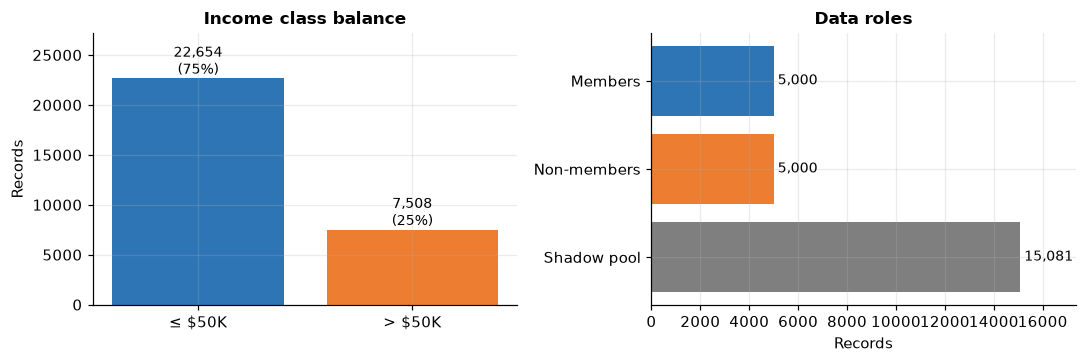

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
counts = pd.Series(y).map({0: '≤ $50K', 1: '> $50K'}).value_counts()
ax[0].bar(counts.index, counts.values, color=[C['member'], C['nonmember']])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f'{v:,}\n({v/len(y):.0%})', ha='center', va='bottom', fontsize=9)
ax[0].set_title('Income class balance'); ax[0].set_ylabel('Records'); ax[0].set_ylim(0, counts.max() * 1.2)

roles = pd.Series({'Members': len(y_in), 'Non-members': len(y_out), 'Shadow pool': len(y_shadow)})
ax[1].barh(roles.index[::-1], roles.values[::-1], color=[C['guess'], C['nonmember'], C['member']])
for i, v in enumerate(roles.values[::-1]):
    ax[1].text(v, i, f' {v:,}', va='center', fontsize=9)
ax[1].set_title('Data roles'); ax[1].set_xlabel('Records'); ax[1].set_xlim(0, roles.max() * 1.15)
save('01_dataset_overview')

## 2. Why the attack works
Train the unrestricted target forest and compare its confidence on members vs non-members.

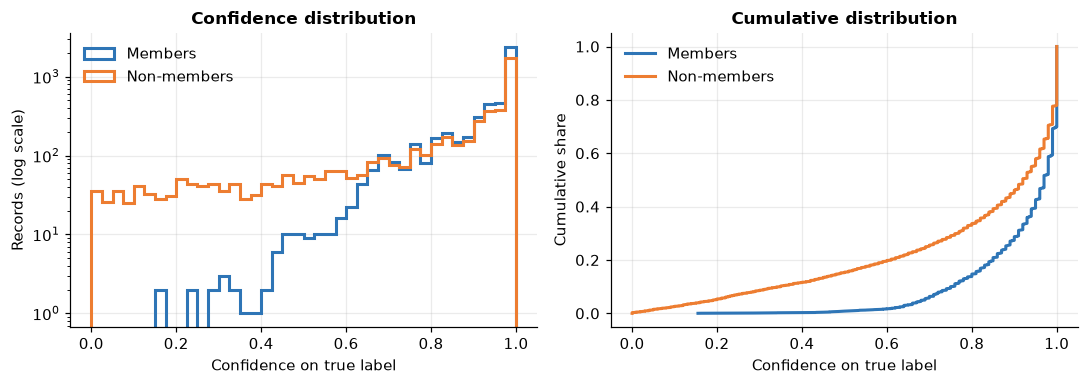

,mean_confidence,share_conf_eq_1,accuracy
Members,0.920,0.302,0.992
Non-members,0.798,0.222,0.847


In [5]:
target = forest().fit(X_in, y_in)
conf_in = true_label_confidence(target, X_in, y_in)
conf_out = true_label_confidence(target, X_out, y_out)
conf_scores = np.r_[conf_in, conf_out]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.linspace(0, 1, 41)
ax[0].hist(conf_in, bins=bins, histtype='step', lw=2, color=C['member'], label='Members')
ax[0].hist(conf_out, bins=bins, histtype='step', lw=2, color=C['nonmember'], label='Non-members')
ax[0].set_yscale('log'); ax[0].set_xlabel('Confidence on true label'); ax[0].set_ylabel('Records (log scale)')
ax[0].set_title('Confidence distribution'); ax[0].legend()

for s, name, col in [(conf_in, 'Members', C['member']), (conf_out, 'Non-members', C['nonmember'])]:
    xs = np.sort(s); ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=col, lw=2, label=name)
ax[1].set_xlabel('Confidence on true label'); ax[1].set_ylabel('Cumulative share')
ax[1].set_title('Cumulative distribution'); ax[1].legend(loc='upper left')
save('02_confidence_distributions')

table1 = pd.DataFrame({
    'mean_confidence': [conf_in.mean(), conf_out.mean()],
    'share_conf_eq_1': [(conf_in == 1).mean(), (conf_out == 1).mean()],
    'accuracy': [accuracy_score(y_in, target.predict(X_in)), accuracy_score(y_out, target.predict(X_out))],
}, index=['Members', 'Non-members'])
table1

## 3. Memorization vs leakage
Random forests from shallow to unrestricted depth, repeated over 5 random member/non-member splits. Attack: confidence threshold.

In [6]:
DEPTHS = [2, 4, 6, 8, 10, 12, 15, 20, None]
SEEDS = [1, 2, 3, 4, 5]

rows = []
for seed in SEEDS:
    Xi, Xo, yi, yo = train_test_split(X_target, y_target, train_size=5000, test_size=5000, random_state=seed)
    labels = np.r_[np.ones(len(yi)), np.zeros(len(yo))]
    for depth in DEPTHS:
        m = forest(depth).fit(Xi, yi)
        tr, te = accuracy_score(yi, m.predict(Xi)), accuracy_score(yo, m.predict(Xo))
        s = np.r_[true_label_confidence(m, Xi, yi), true_label_confidence(m, Xo, yo)]
        rows.append({'seed': seed, 'max_depth': 'None' if depth is None else str(depth),
                     'train_acc': tr, 'test_acc': te, 'gap': tr - te, **evaluate(labels, s)})

depth_runs = pd.DataFrame(rows)
order = [str(d) if d else 'None' for d in DEPTHS]
agg = depth_runs.groupby('max_depth', sort=False).agg(['mean', 'std']).drop(columns='seed').reindex(order)

table2 = pd.DataFrame({c: agg[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + agg[(c, 'std')].map('{:.3f}'.format)
                       for c in ['train_acc', 'test_acc', 'gap', 'attack_auc']})
table2

,train_acc,test_acc,gap,attack_auc
max_depth,,,,
2,0.766 ± 0.003,0.767 ± 0.003,-0.001 ± 0.004,0.503 ± 0.005
4,0.826 ± 0.010,0.826 ± 0.007,0.000 ± 0.007,0.505 ± 0.004
6,0.847 ± 0.005,0.842 ± 0.004,0.005 ± 0.007,0.508 ± 0.004
8,0.862 ± 0.002,0.852 ± 0.003,0.010 ± 0.004,0.515 ± 0.004
10,0.874 ± 0.002,0.855 ± 0.003,0.019 ± 0.004,0.523 ± 0.004
12,0.891 ± 0.002,0.856 ± 0.004,0.035 ± 0.005,0.535 ± 0.004
15,0.919 ± 0.001,0.856 ± 0.003,0.063 ± 0.004,0.554 ± 0.004
20,0.963 ± 0.003,0.853 ± 0.006,0.109 ± 0.005,0.585 ± 0.005
None,0.992 ± 0.000,0.842 ± 0.006,0.150 ± 0.007,0.627 ± 0.007


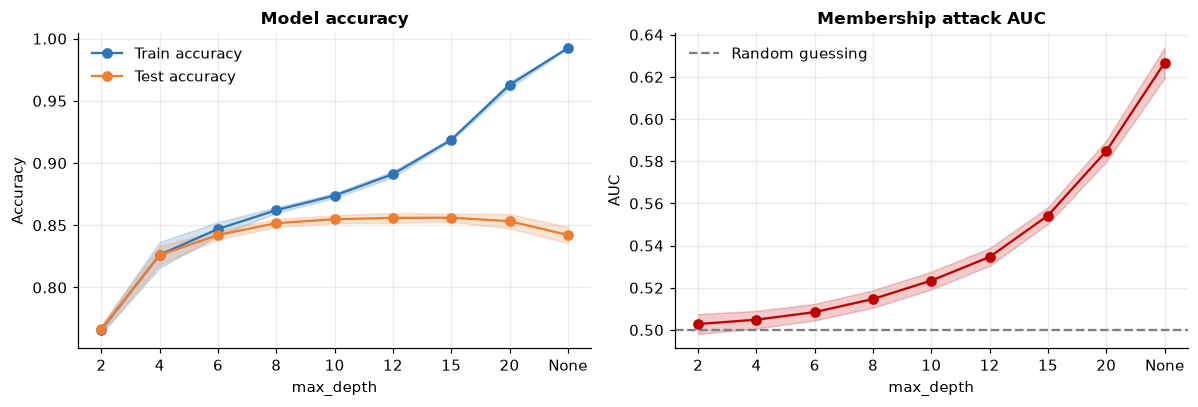

In [7]:
x = np.arange(len(order))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for col, name, c in [('train_acc', 'Train accuracy', C['member']), ('test_acc', 'Test accuracy', C['nonmember'])]:
    m, s = agg[(col, 'mean')], agg[(col, 'std')]
    ax[0].plot(x, m, marker='o', color=c, label=name); ax[0].fill_between(x, m - s, m + s, color=c, alpha=0.2)
ax[0].set_title('Model accuracy'); ax[0].set_ylabel('Accuracy'); ax[0].legend()

m, s = agg[('attack_auc', 'mean')], agg[('attack_auc', 'std')]
ax[1].plot(x, m, marker='o', color=C['attack']); ax[1].fill_between(x, m - s, m + s, color=C['attack'], alpha=0.2)
ax[1].axhline(0.5, ls='--', color=C['guess'], label='Random guessing'); ax[1].legend(loc='upper left')
ax[1].set_title('Membership attack AUC'); ax[1].set_ylabel('AUC')
for a in ax:
    a.set_xticks(x, order); a.set_xlabel('max_depth')
save('03_accuracy_and_leakage_vs_depth')

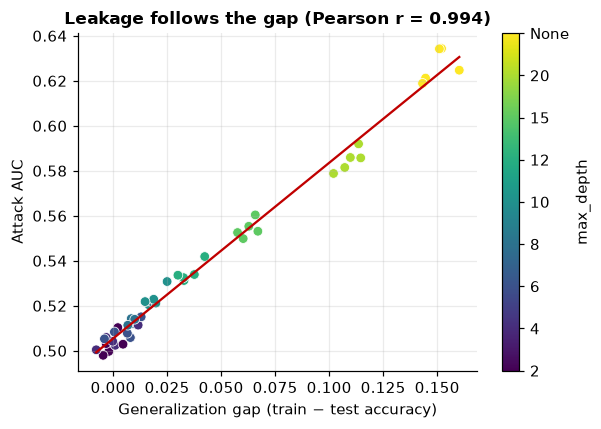

In [8]:
r_gap, p_gap = pearsonr(depth_runs['gap'], depth_runs['attack_auc'])
fig, ax = plt.subplots(figsize=(5.6, 4))
sc = ax.scatter(depth_runs['gap'], depth_runs['attack_auc'], c=[order.index(d) for d in depth_runs['max_depth']],
                cmap='viridis', s=40, edgecolor='white', lw=0.5)
coef = np.polyfit(depth_runs['gap'], depth_runs['attack_auc'], 1)
gx = np.linspace(depth_runs['gap'].min(), depth_runs['gap'].max(), 50)
ax.plot(gx, np.polyval(coef, gx), color=C['attack'], lw=1.5)
cb = plt.colorbar(sc, ticks=range(len(order))); cb.ax.set_yticklabels(order); cb.set_label('max_depth')
ax.set_xlabel('Generalization gap (train − test accuracy)'); ax.set_ylabel('Attack AUC')
ax.set_title(f'Leakage follows the gap (Pearson r = {r_gap:.3f})')
save('04_gap_vs_leakage')

## 4. Shadow model attack
The attacker trains 4 shadow forests on their own data, then a gradient boosting attack model on the shadows' outputs (Shokri et al., 2017). Assumes the attacker knows the target is a random forest.

In [9]:
def attack_features(model, X, y):
    p = model.predict_proba(X)
    return np.c_[np.sort(p, axis=1), p[np.arange(len(y)), y], y]

N_SHADOWS = 8
shadow_X, shadow_y = [], []
for k in range(N_SHADOWS):
    s_in, s_out, sy_in, sy_out = train_test_split(X_shadow, y_shadow, train_size=5000, test_size=5000, random_state=10 + k)
    sm = forest(seed=k).fit(s_in, sy_in)
    shadow_X.append(np.vstack([attack_features(sm, s_in, sy_in), attack_features(sm, s_out, sy_out)]))
    shadow_y.append(np.r_[np.ones(len(sy_in)), np.zeros(len(sy_out))])

target_features = np.vstack([attack_features(target, X_in, y_in), attack_features(target, X_out, y_out)])

def shadow_attack(k):
    am = GradientBoostingClassifier(random_state=0).fit(np.vstack(shadow_X[:k]), np.concatenate(shadow_y[:k]))
    return am.predict_proba(target_features)[:, 1]

shadow_scores = shadow_attack(4)
table3 = pd.DataFrame([evaluate(members, conf_scores), evaluate(members, shadow_scores)],
                      index=['Confidence threshold', 'Shadow models (k=4)'])
table3

,attack_auc,tpr_at_1pct_fpr
Confidence threshold,0.621,0.000
Shadow models (k=4),0.654,0.025


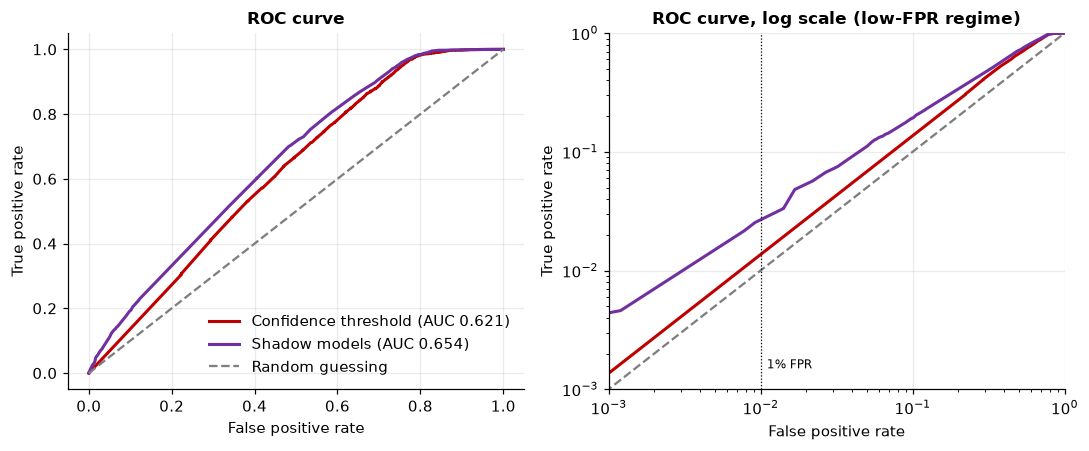

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for name, s, c in [('Confidence threshold', conf_scores, C['attack']), ('Shadow models', shadow_scores, C['shadow'])]:
    fpr, tpr, _ = roc_curve(members, s)
    auc = roc_auc_score(members, s)
    ax[0].plot(fpr, tpr, color=c, lw=2, label=f'{name} (AUC {auc:.3f})')
    ax[1].plot(fpr, tpr, color=c, lw=2, label=name)
for a in ax:
    a.plot([1e-4, 1], [1e-4, 1], '--', color=C['guess'], label='Random guessing')
    a.set_xlabel('False positive rate'); a.set_ylabel('True positive rate')
ax[0].set_title('ROC curve'); ax[0].legend(loc='lower right')
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].set_xlim(1e-3, 1); ax[1].set_ylim(1e-3, 1)
ax[1].axvline(0.01, color='black', lw=0.8, ls=':'); ax[1].text(0.011, 0.0015, '1% FPR', fontsize=8)
ax[1].set_title('ROC curve, log scale (low-FPR regime)')
save('05_roc_attacks')

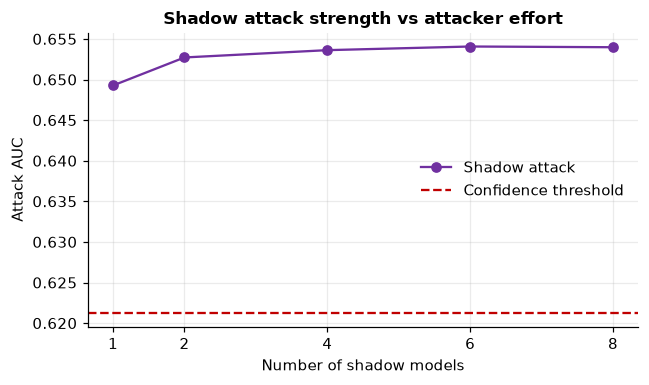

,shadow_models,attack_auc,tpr_at_1pct_fpr
0,1,0.649,0.019
1,2,0.653,0.011
2,4,0.654,0.025
3,6,0.654,0.023
4,8,0.654,0.018


In [11]:
ks = [1, 2, 4, 6, 8]
shadow_k = pd.DataFrame([{'shadow_models': k, **evaluate(members, shadow_attack(k))} for k in ks])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(shadow_k['shadow_models'], shadow_k['attack_auc'], marker='o', color=C['shadow'], label='Shadow attack')
ax.axhline(table3.loc['Confidence threshold', 'attack_auc'], ls='--', color=C['attack'], label='Confidence threshold')
ax.set_xticks(ks); ax.set_xlabel('Number of shadow models'); ax.set_ylabel('Attack AUC')
ax.set_title('Shadow attack strength vs attacker effort'); ax.legend()
save('06_shadow_models_count')
shadow_k

## 5. Training set size
Smaller training sets give each record more influence. Unrestricted forest, 3 seeds per size.

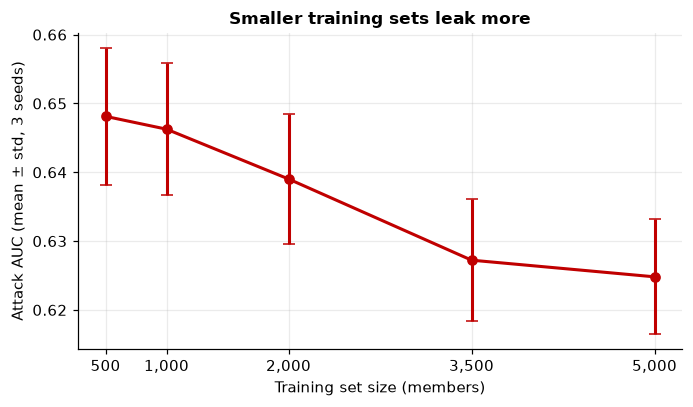

,test_acc,attack_auc,tpr_at_1pct_fpr
train_size,,,
500,0.831,0.648,0.0
1000,0.844,0.646,0.0
2000,0.842,0.639,0.0
3500,0.842,0.627,0.0
5000,0.846,0.625,0.0


In [12]:
SIZES = [500, 1000, 2000, 3500, 5000]
rows = []
for seed in [1, 2, 3]:
    for n in SIZES:
        Xi, Xo, yi, yo = train_test_split(X_target, y_target, train_size=n, test_size=n, random_state=seed)
        m = forest().fit(Xi, yi)
        s = np.r_[true_label_confidence(m, Xi, yi), true_label_confidence(m, Xo, yo)]
        rows.append({'train_size': n, 'test_acc': accuracy_score(yo, m.predict(Xo)),
                     **evaluate(np.r_[np.ones(n), np.zeros(n)], s)})
size_res = pd.DataFrame(rows).groupby('train_size').agg(['mean', 'std'])

fig, ax1 = plt.subplots(figsize=(6.4, 3.8))
m, s = size_res[('attack_auc', 'mean')], size_res[('attack_auc', 'std')]
ax1.errorbar(SIZES, m, yerr=s, marker='o', color=C['attack'], capsize=4, lw=2)
ax1.set_xticks(SIZES, [f'{n:,}' for n in SIZES])
ax1.set_xlabel('Training set size (members)'); ax1.set_ylabel('Attack AUC (mean ± std, 3 seeds)')
ax1.set_title('Smaller training sets leak more')
save('07_training_size_vs_leakage')
size_res.xs('mean', axis=1, level=1)

## 6. Defenses
| Defense | Change |
|---|---|
| Round outputs | Probabilities rounded to 1 decimal |
| Label only | Only the predicted label is returned |
| Regularization | `max_depth=10` |

In [13]:
proba_in, proba_out = target.predict_proba(X_in), target.predict_proba(X_out)
rounded = np.r_[np.round(proba_in, 1)[np.arange(len(y_in)), y_in], np.round(proba_out, 1)[np.arange(len(y_out)), y_out]]
label_only = np.r_[target.predict(X_in) == y_in, target.predict(X_out) == y_out].astype(float)
regular = forest(10).fit(X_in, y_in)
regular_scores = np.r_[true_label_confidence(regular, X_in, y_in), true_label_confidence(regular, X_out, y_out)]

defenses = []
for name, model, s in [('No defense', target, conf_scores), ('Round outputs', target, rounded),
                       ('Label only', target, label_only), ('Regularization', regular, regular_scores)]:
    defenses.append({'defense': name, 'test_acc': accuracy_score(y_out, model.predict(X_out)), **evaluate(members, s)})
table4 = pd.DataFrame(defenses).set_index('defense')
table4

,test_acc,attack_auc,tpr_at_1pct_fpr
defense,,,
No defense,0.847,0.621,0.000
Round outputs,0.847,0.618,0.000
Label only,0.847,0.572,0.000
Regularization,0.858,0.520,0.008


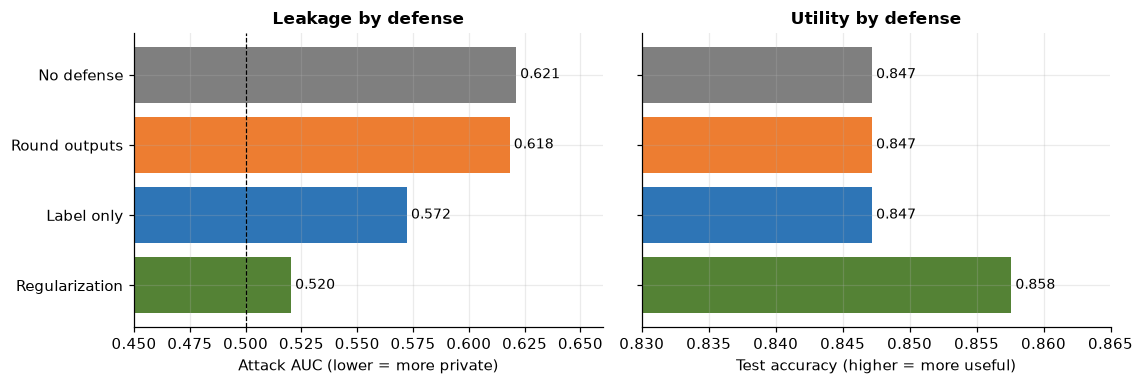

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
cols = [C['guess'], C['nonmember'], C['member'], C['good']]
ax[0].barh(table4.index[::-1], table4['attack_auc'][::-1], color=cols[::-1])
ax[0].axvline(0.5, ls='--', color='black', lw=0.8)
for i, v in enumerate(table4['attack_auc'][::-1]):
    ax[0].text(v, i, f' {v:.3f}', va='center', fontsize=9)
ax[0].set_xlim(0.45, 0.66); ax[0].set_xlabel('Attack AUC (lower = more private)'); ax[0].set_title('Leakage by defense')

ax[1].barh(table4.index[::-1], table4['test_acc'][::-1], color=cols[::-1])
for i, v in enumerate(table4['test_acc'][::-1]):
    ax[1].text(v, i, f' {v:.3f}', va='center', fontsize=9)
ax[1].set_xlim(0.83, 0.865); ax[1].set_xlabel('Test accuracy (higher = more useful)'); ax[1].set_title('Utility by defense')
ax[1].set_yticklabels([])
save('08_defense_comparison')

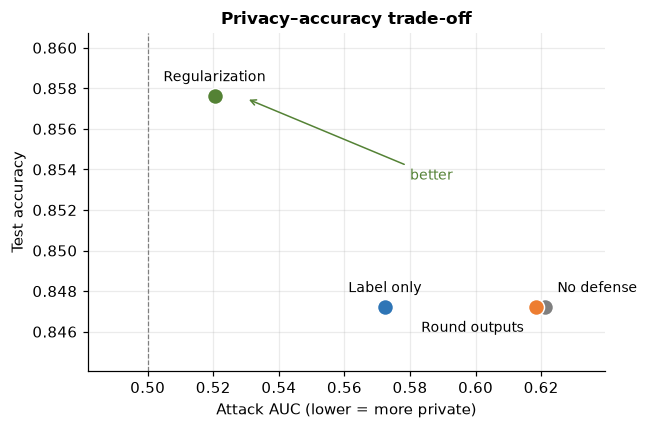

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
offsets = {'No defense': (8, 10, 'left'), 'Round outputs': (-8, -16, 'right'),
           'Label only': (0, 10, 'center'), 'Regularization': (0, 10, 'center')}
for (name, row), c in zip(table4.iterrows(), cols):
    dx, dy, ha = offsets[name]
    ax.scatter(row['attack_auc'], row['test_acc'], s=110, color=c, zorder=3, edgecolor='white')
    ax.annotate(name, (row['attack_auc'], row['test_acc']), textcoords='offset points', xytext=(dx, dy), ha=ha, fontsize=9)
ax.axvline(0.5, ls='--', color=C['guess'], lw=0.8)
ax.annotate('better', xy=(0.53, 0.8575), xytext=(0.58, 0.8535), fontsize=9, color=C['good'],
            arrowprops=dict(arrowstyle='->', color=C['good']))
ax.margins(x=0.15, y=0.3)
ax.set_xlabel('Attack AUC (lower = more private)'); ax.set_ylabel('Test accuracy')
ax.set_title('Privacy–accuracy trade-off')
save('09_privacy_vs_accuracy')

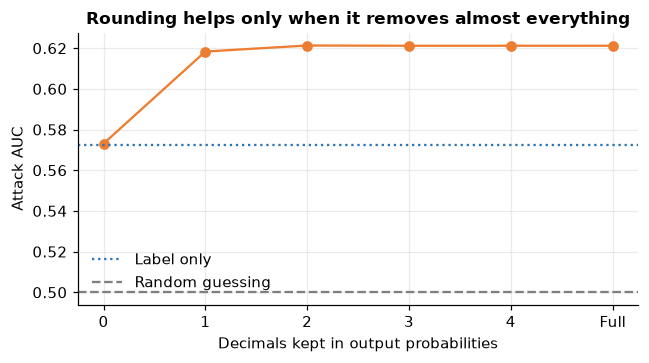

,decimals,attack_auc,tpr_at_1pct_fpr
0,0,0.573,0.0
1,1,0.618,0.0
2,2,0.621,0.0
3,3,0.621,0.0
4,4,0.621,0.0
5,Full,0.621,0.0


In [16]:
rows = []
for d in [0, 1, 2, 3, 4]:
    s = np.r_[np.round(proba_in, d)[np.arange(len(y_in)), y_in], np.round(proba_out, d)[np.arange(len(y_out)), y_out]]
    rows.append({'decimals': str(d), **evaluate(members, s)})
rows.append({'decimals': 'Full', **evaluate(members, conf_scores)})
rounding = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(rounding['decimals'], rounding['attack_auc'], marker='o', color=C['nonmember'])
ax.axhline(table4.loc['Label only', 'attack_auc'], ls=':', color=C['member'], label='Label only')
ax.axhline(0.5, ls='--', color=C['guess'], label='Random guessing')
ax.set_xlabel('Decimals kept in output probabilities'); ax.set_ylabel('Attack AUC')
ax.set_title('Rounding helps only when it removes almost everything'); ax.legend()
save('10_rounding_precision')
rounding

## 7. Who is most at risk
Records grouped by how common their profile (native country + occupation) is. 95% bootstrap intervals.

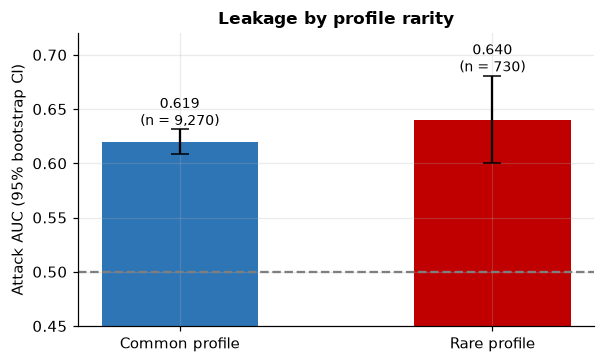

,records,attack_auc,ci_low,ci_high
group,,,,
Common profile,9270,0.619,0.609,0.631
Rare profile,730,0.640,0.600,0.681


In [17]:
adult_target, _ = train_test_split(adult, test_size=0.5, random_state=0)
adult_in, adult_out = train_test_split(adult_target, train_size=5000, test_size=5000, random_state=1)
profile = pd.concat([adult_in, adult_out]).pipe(lambda d: d['native_country'] + ' / ' + d['occupation'])
group = np.where(profile.map(profile.value_counts()).values < 20, 'Rare profile', 'Common profile')

rng = np.random.default_rng(0)
risk = []
for g in ['Common profile', 'Rare profile']:
    idx = np.where(group == g)[0]
    boots = []
    for _ in range(1000):
        b = rng.choice(idx, len(idx))
        if members[b].min() != members[b].max():
            boots.append(roc_auc_score(members[b], conf_scores[b]))
    risk.append({'group': g, 'records': len(idx), 'attack_auc': roc_auc_score(members[idx], conf_scores[idx]),
                 'ci_low': np.percentile(boots, 2.5), 'ci_high': np.percentile(boots, 97.5)})
table5 = pd.DataFrame(risk).set_index('group')

fig, ax = plt.subplots(figsize=(5.6, 3.4))
err = [table5['attack_auc'] - table5['ci_low'], table5['ci_high'] - table5['attack_auc']]
ax.bar(table5.index, table5['attack_auc'], yerr=err, capsize=6, color=[C['member'], C['attack']], width=0.5)
for i, (g, row) in enumerate(table5.iterrows()):
    ax.text(i, row['ci_high'] + 0.004, f"{row['attack_auc']:.3f}\n(n = {int(row['records']):,})", ha='center', fontsize=9)
ax.axhline(0.5, ls='--', color=C['guess']); ax.set_ylim(0.45, 0.72)
ax.set_ylabel('Attack AUC (95% bootstrap CI)'); ax.set_title('Leakage by profile rarity')
save('11_risk_by_profile')
table5

## 8. Summary

In [18]:
summary = pd.DataFrame({'Result': [
    'Attack AUC, max_depth=2 → unrestricted (mean of 5 seeds)',
    'Correlation between generalization gap and attack AUC',
    'Confidence attack AUC / TPR @ 1% FPR',
    'Shadow model attack AUC / TPR @ 1% FPR',
    'Attack AUC at 500 vs 5,000 training records',
    'Best defense: regularization, attack AUC / test accuracy',
    'Attack AUC, rare vs common profiles',
], 'Value': [
    f"{agg.loc['2', ('attack_auc', 'mean')]:.3f} → {agg.loc['None', ('attack_auc', 'mean')]:.3f}",
    f"r = {r_gap:.3f}",
    f"{table3.iloc[0, 0]:.3f} / {table3.iloc[0, 1]:.3f}",
    f"{table3.iloc[1, 0]:.3f} / {table3.iloc[1, 1]:.3f}",
    f"{size_res.loc[500, ('attack_auc', 'mean')]:.3f} vs {size_res.loc[5000, ('attack_auc', 'mean')]:.3f}",
    f"{table4.loc['Regularization', 'attack_auc']:.3f} / {table4.loc['Regularization', 'test_acc']:.3f}",
    f"{table5.loc['Rare profile', 'attack_auc']:.3f} vs {table5.loc['Common profile', 'attack_auc']:.3f}",
]})
summary.style.hide(axis='index')

Result,Value
"Attack AUC, max_depth=2 → unrestricted (mean of 5 seeds)",0.503 → 0.627
Correlation between generalization gap and attack AUC,r = 0.994
Confidence attack AUC / TPR @ 1% FPR,0.621 / 0.000
Shadow model attack AUC / TPR @ 1% FPR,0.654 / 0.025
"Attack AUC at 500 vs 5,000 training records",0.648 vs 0.625
"Best defense: regularization, attack AUC / test accuracy",0.520 / 0.858
"Attack AUC, rare vs common profiles",0.640 vs 0.619


**Key takeaways**
- Leakage tracks overfitting: the larger the train–test gap, the stronger the attack.
- Shadow models beat the simple confidence attack, especially at low false positive rates.
- Regularization is the most effective defense and also improves test accuracy.
- Output rounding barely helps; label-only access reduces but does not remove leakage.
- Rare-profile records show a slightly higher attack AUC, but the 95% intervals overlap, so the difference is not conclusive.

**Limitations:** random forests on one tabular dataset; attacker knows the model type.
**Next steps:** DP-SGD defense, LiRA attack (Carlini et al., 2022), neural networks and image data.